## Code

In [1]:
import numpy as np
import pandas as pd

# Create a synthetic dataset containing age (usia), income (pendapatan), and spending score (skor_belanja)
np.random.seed(42)
data = {
    'usia': np.random.randint(18, 70, size=200),
    'pendapatan': np.random.randint(15, 137, size=200) * 1000,
    'skor_belanja': np.random.randint(1, 100, size=200)
}
df = pd.DataFrame(data)
display(df.head())

,usia,pendapatan,skor_belanja
0,56,84000,64
1,69,86000,49
2,46,41000,17
3,32,23000,44
4,60,76000,92


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
X_scaled = StandardScaler().fit_transform(df)


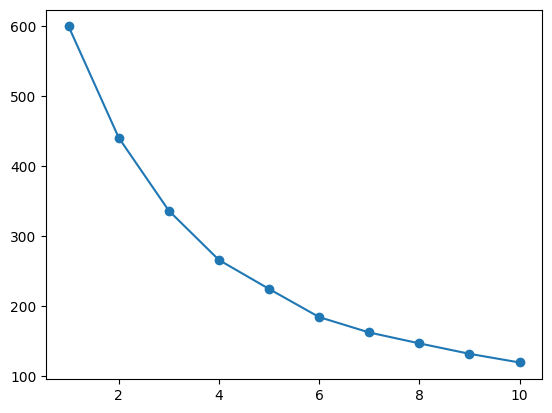

In [3]:
from sklearn.cluster import KMeans
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled); inertias.append(km.inertia_)
plt.plot(range(1,11), inertias, marker='o'); plt.show()


In [10]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())


cluster
2    70
0    68
1    62
Name: count, dtype: int64


In [11]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))


0.2611709464764331


In [12]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil


         usia  pendapatan  skor_belanja
cluster                                
0        40.1    104279.4          28.2
1        30.4     54483.9          69.6
2        58.2     61657.1          54.7


## Latihan Mandiri

1. Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.
K=5 memiliki struktur cluster yang lebih baik (silhouette score lebih tinggi) dibandingkan K=3

2. Jalankan K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?
Secara angka, silhouette score tanpa scaling terlihat jauh lebih tinggi.Namun, ini terjadi karena fitur 'pendapatan' memiliki rentang nilai yang sangat besar (puluhan ribu),
sehingga mendominasi perhitungan jarak jauh melebihi 'usia' dan 'skor_belanja'.
Tanpa scaling, K-Means hanya mengelompokkan data berdasarkan pendapatan saja (seolah fitur lain tidak ada).
Oleh karena itu, scaling (StandardScaler) sangat penting agar seluruh fitur berkontribusi secara seimbang.


3. Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y).

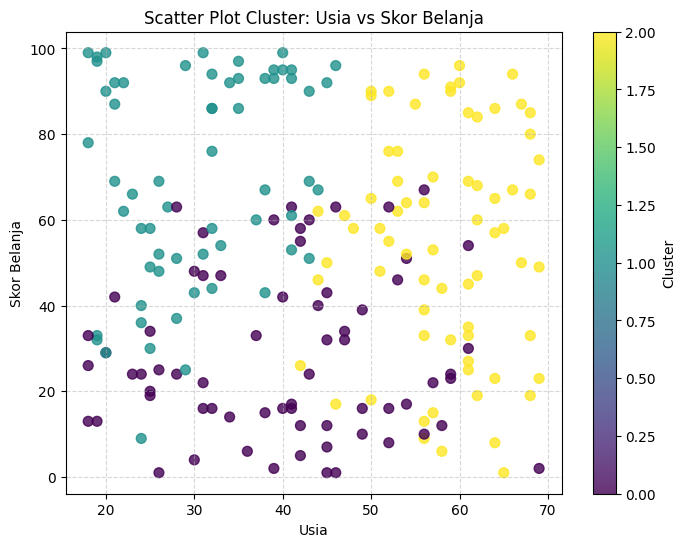

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
scatter = plt.scatter(df['usia'], df['skor_belanja'], c=df['cluster'], cmap='viridis', s=50, alpha=0.8)

plt.title('Scatter Plot Cluster: Usia vs Skor Belanja')
plt.xlabel('Usia')
plt.ylabel('Skor Belanja')
plt.colorbar(scatter, label='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Refreksi Diri

1. Bagaimana K-Means menemukan kelompok tanpa label?
K-Means menemukan kelompok berdasarkan kemiripan karakteristik dan kedekatan jarak antar-data, bukan berdasarkan label yang diberikan manusia.

2. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?
Titik ketika penurunan WCSS mulai melandai menyerupai bentuk siku, sehingga K = 3 dipilih sebagai jumlah cluster yang relatif seimbang antara kekompakan kelompok dan kompleksitas model.

3. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?
Karena K-Means menggunakan perhitungan jarak, fitur pendapatan dapat mendominasi jarak akibat rentang angkanya yang jauh lebih besar, meskipun fitur tersebut belum tentu paling penting untuk pengelompokan.